# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import ZurichSummerDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 20


2025-02-24 08:33:44,761 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


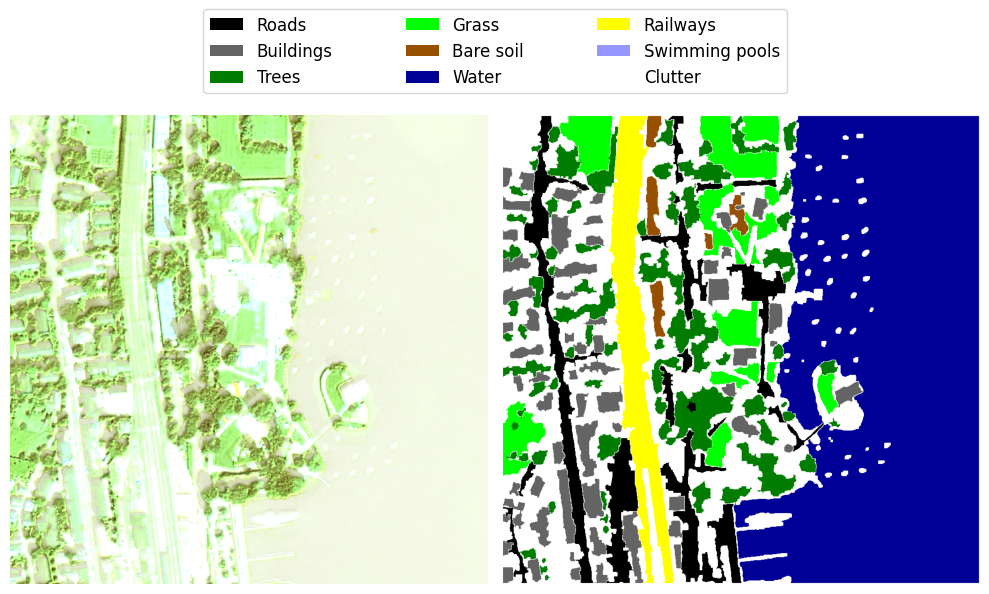

2025-02-24 08:33:59,944 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


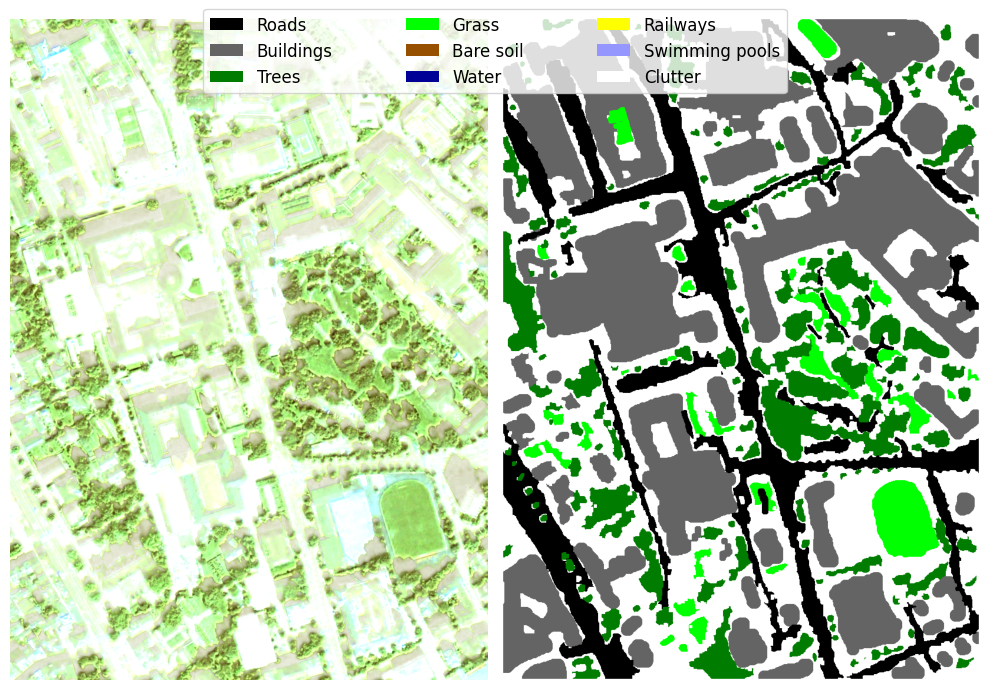

2025-02-24 08:34:32,572 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


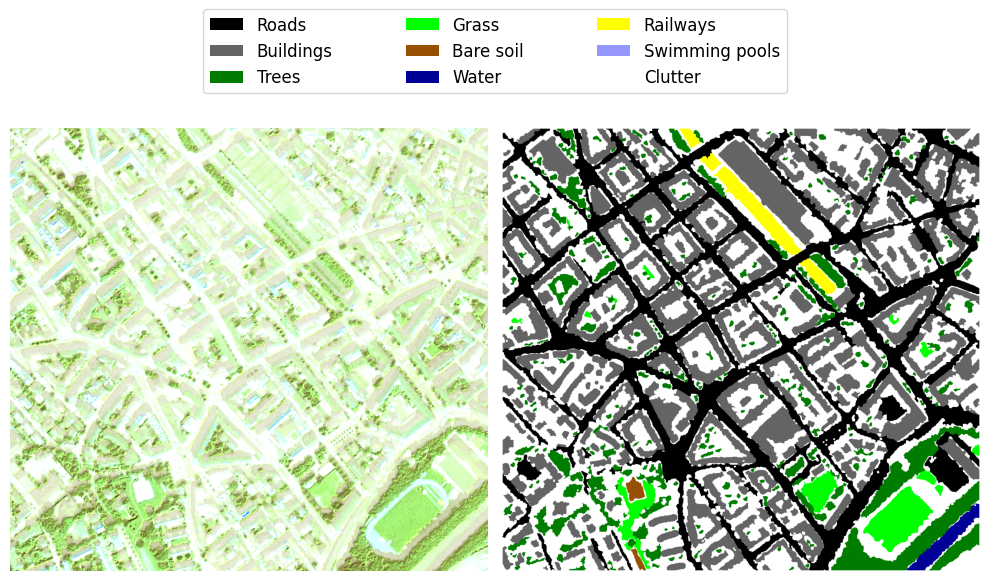

In [20]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/Zurich_summer",
    "selection": "all"
}
dataset = ZurichSummerDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(3);
dataset.show_image(8);

In [37]:
dataset.data_distribution_table()

,Number of pixels
Roads,3802379.0
Buildings,5374411.0
Trees,2531661.0
Grass,1864547.0
Bare soil,234618.0
Water,1267421.0
Railways,342084.0
Swimming pools,33525.0
Clutter,10583567.0


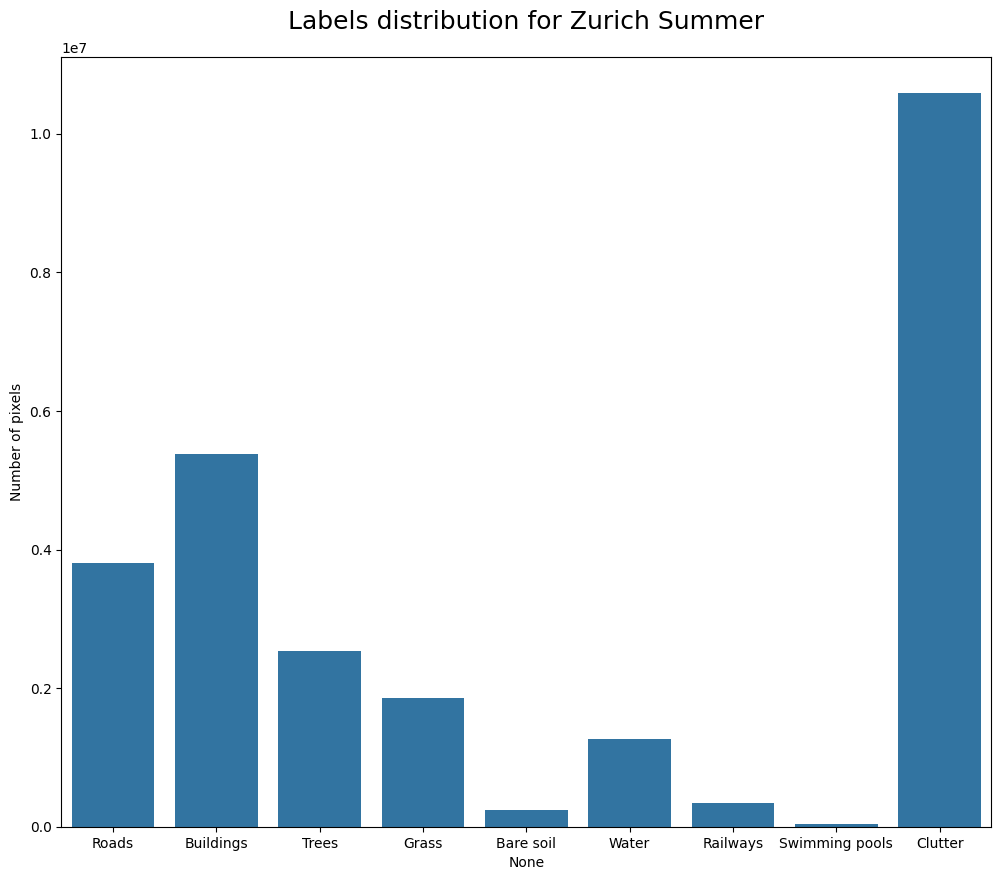

In [38]:
dataset.data_distribution_barchart();

## Load training data

In [4]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/Zurich_summer",
    "csv_file": "/home/dragik/data/FAIR_EO/Zurich_summer/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = ZurichSummerDataset(train_dataset_config)
len(train_dataset)

16

## Create the model

In [5]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/Zurich_summer"
model_config = {
    "num_classes": 9, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-02-26 07:47:23,050 INFO Starting training.
training: 100%|██████████| 4/4 [01:40<00:00, 25.22s/it]
2025-02-26 07:49:04,024 INFO epoch: 1, time: 101, loss:  0.82084
testing on train set: 100%|██████████| 4/4 [02:12<00:00, 33.16s/it]
2025-02-26 07:51:18,761 INFO IOU:0.04430041001776763, IOU mean:0.05816527935895783, IOU per Class:[0.07257283 0.11695875 0.08856528 0.03284754 0.00613752 0.14363286
 0.00958285 0.00054726 0.05264263]
training: 100%|██████████| 4/4 [01:39<00:00, 24.91s/it]
2025-02-26 07:52:58,420 INFO epoch: 2, time: 100, loss:  0.81192
testing on train set: 100%|██████████| 4/4 [01:52<00:00, 28.03s/it]
2025-02-26 07:54:50,554 INFO IOU:0.06818648002786051, IOU mean:0.0829914169218357, IOU per Class:[0.07949944 0.13880955 0.08407711 0.03268917 0.01236607 0.22197365
 0.00952493 0.         0.16798283]
training: 100%|██████████| 4/4 [01:51<00:00, 27.96s/it] 
2025-02-26 07:56:42,395 INFO epoch: 3, time: 112, loss:  0.80473
testing on train set: 100%|██████████| 4/4 [01:52<00:

## Evaluate the model

In [7]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/Zurich_summer",
    "csv_file": "/home/dragik/data/FAIR_EO/Zurich_summer/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = ZurichSummerDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/Zurich_summer/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2


2025-02-26 08:36:32,107 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Zurich_summer/checkpoint.pth.tar
2025-02-26 08:36:32,585 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Zurich_summer/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 1/1 [00:29<00:00, 29.52s/it]


[{'IOU': 0.10197919568689155,
  'IOU mean': 0.06707331714942714,
  'IOU per Class': array([0.14949233, 0.10456165, 0.05292723, 0.05252762, 0.        ,
         0.00129296, 0.        , 0.        , 0.24285806])}]

## Predictions

2025-02-26 08:39:23,513 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Zurich_summer/checkpoint.pth.tar
2025-02-26 08:39:23,873 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Zurich_summer/checkpoint.pth.tar at epoch 11
2025-02-26 08:39:24,054 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-02-26 08:39:24,333 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


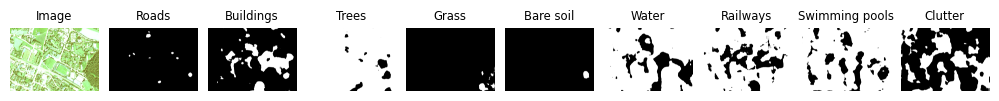

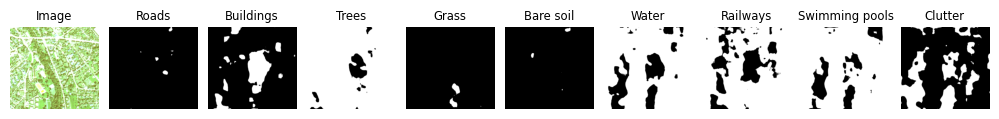

In [10]:
model_path = "/home/dragik/data/FAIR_EO/Zurich_summer/checkpoint.pth.tar"
labels = ["Roads","Buildings","Trees","Grass","Bare soil","Water","Railways","Swimming pools","Clutter"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 7})
csv_file = "/home/dragik/data/FAIR_EO/Zurich_summer/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('/home/dragik/data/FAIR_EO/Zurich_summer/' + test_list[0])
image = image[:,:,0:3] #RGB
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/Zurich_summer/' + test_list[1])
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)